# Case study: what drives medical insurance costs?

The previous notebooks introduced each technique on its own dataset. This one puts them together on a single question: **which characteristics of a person explain their yearly medical costs, and how well can we predict them?**

The steps are the ones of a real analysis:

1. look at the data and form hypotheses;
2. fit a first additive model and let the **residual diagnostics** show what it misses;
3. add the structure the plots suggest (an **interaction** and a **curvature** term) and check that it holds on a test set;
4. compare with **ridge, lasso** and a **random forest**;
5. briefly, predict a **cost band** instead of the amount.

**Data:** the [Medical Cost Personal Dataset](https://www.kaggle.com/datasets/mirichoi0218/insurance) from Kaggle: 1,338 US insurance beneficiaries with age, sex, body mass index (BMI), number of children covered, smoking status, region of residence and the medical charges billed by the insurer in one year.

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from patsy import dmatrices
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import LassoCV, LinearRegression, QuantileRegressor, RidgeCV
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from diagnostics import diagnostic_plots

warnings.filterwarnings("ignore", message="kurtosistest only valid")
plt.rcParams["figure.dpi"] = 100

In [2]:
insurance = pd.read_csv("data/insurance.csv")
print(f"{len(insurance)} rows, {insurance.duplicated().sum()} exact duplicate, {insurance.isna().sum().sum()} missing values")
insurance = insurance.drop_duplicates().reset_index(drop=True)
print("smokers:", f"{(insurance['smoker'] == 'yes').mean():.0%}")
print(insurance[["sex", "region"]].apply(lambda c: c.value_counts().to_dict()).to_string())
insurance.describe().T.round(1)

1338 rows, 1 exact duplicate, 0 missing values
smokers: 20%
sex                            {'male': 675, 'female': 662}
region    {'southeast': 364, 'southwest': 325, 'northwes...


,count,mean,std,min,25%,50%,75%,max
age,1337.0,39.2,14.0,18.0,27.0,39.0,51.0,64.0
bmi,1337.0,30.7,6.1,16.0,26.3,30.4,34.7,53.1
children,1337.0,1.1,1.2,0.0,0.0,1.0,2.0,5.0
charges,1337.0,13279.1,12110.4,1121.9,4746.3,9386.2,16657.7,63770.4


Two rows are identical in every column (a 19-year-old man with the same BMI and charges), so one is dropped. Ages range from 18 to 64, BMI from 16 to 53, and charges from about \$1,100 to \$64,000 per year. About 20% of the beneficiaries smoke.

Before looking at the data more closely, we set aside a **test set** of 25%. All the choices below (which variables, which transformations) are made on the training set only, so the test error at the end is an honest estimate of the prediction error on new people.

In [3]:
train, test = train_test_split(insurance, test_size=0.25, random_state=0, stratify=insurance["smoker"])
print(f"training set: {len(train)} people, test set: {len(test)} people")

training set: 1002 people, test set: 335 people


## 1. Exploring the data

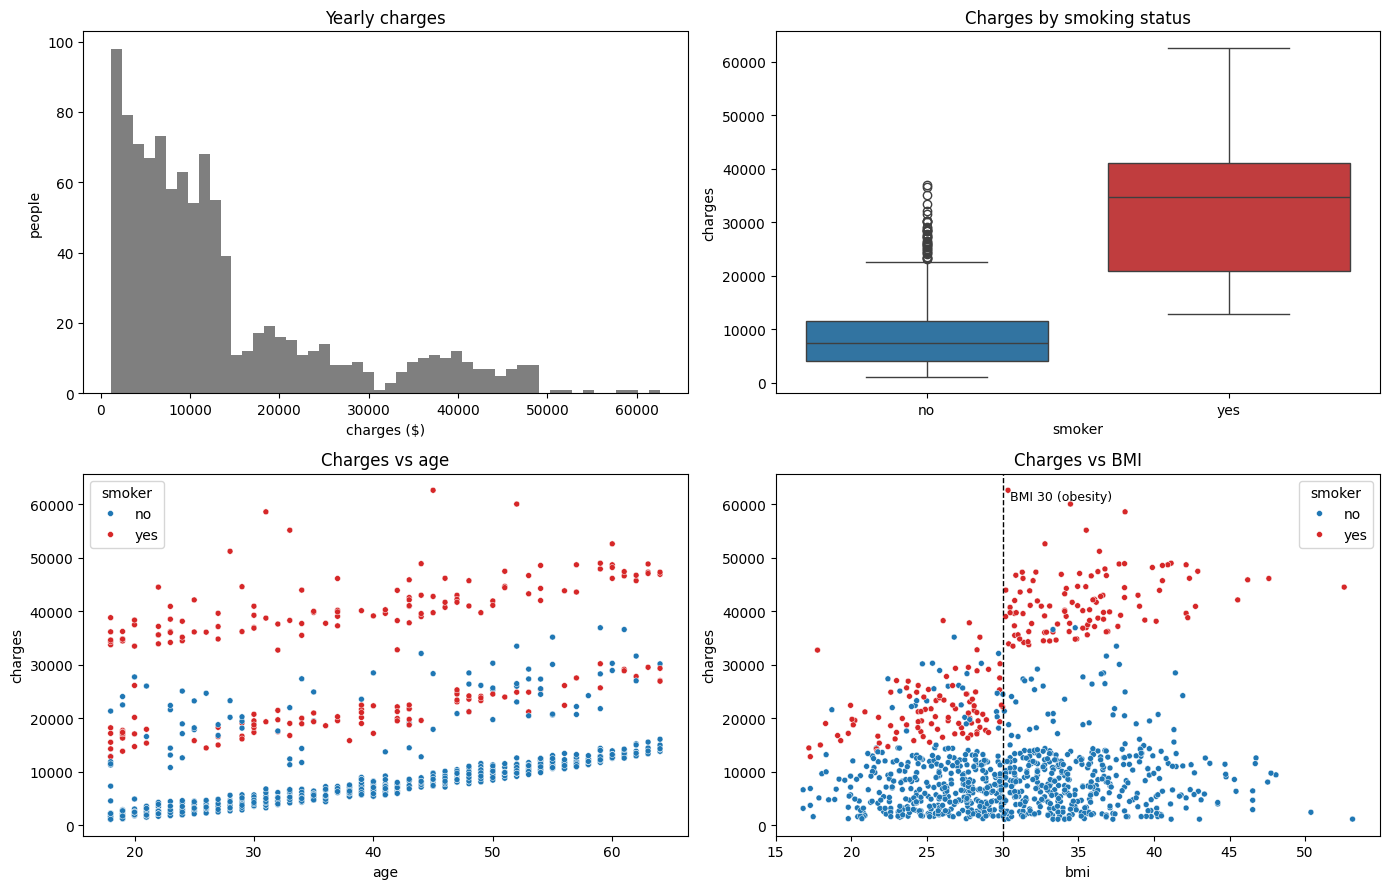

,count,25%,50%,75%
smoker,,,,
no,797.0,4138.0,7421.0,11553.0
yes,205.0,20984.0,34780.0,41034.0


In [4]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
palette = {"no": "tab:blue", "yes": "tab:red"}

axes[0, 0].hist(train["charges"], bins=50, color="tab:grey")
axes[0, 0].set(title="Yearly charges", xlabel="charges ($)", ylabel="people")

sns.boxplot(data=train, x="smoker", y="charges", hue="smoker", palette=palette, ax=axes[0, 1])
axes[0, 1].set(title="Charges by smoking status")

sns.scatterplot(data=train, x="age", y="charges", hue="smoker", palette=palette, s=18, ax=axes[1, 0])
axes[1, 0].set(title="Charges vs age")

sns.scatterplot(data=train, x="bmi", y="charges", hue="smoker", palette=palette, s=18, ax=axes[1, 1])
axes[1, 1].axvline(30, color="black", ls="--", lw=1)
axes[1, 1].text(30.5, train["charges"].max(), "BMI 30 (obesity)", va="top", fontsize=9)
axes[1, 1].set(title="Charges vs BMI")
fig.tight_layout()
plt.show()

train.groupby("smoker")["charges"].describe()[["count", "25%", "50%", "75%"]].round(0)

- **Charges are very skewed**: most people cost less than \$15k per year, and a long tail goes up to \$60k.
- **Smoking is by far the strongest factor.** The median smoker costs about \$35k per year, almost five times the \$7k of a non-smoker.
- **Charges grow with age in three parallel bands.** The lowest band contains almost only non-smokers and curves slightly upwards. The middle band mixes smokers and non-smokers, the highest band contains only smokers.
- **BMI matters only for smokers, and as a threshold.** Non-smokers cost about the same at any BMI. Smokers split in two groups: around \$20k below BMI 30 and around \$40k above it. Obesity and smoking together are what puts a person in the highest band.

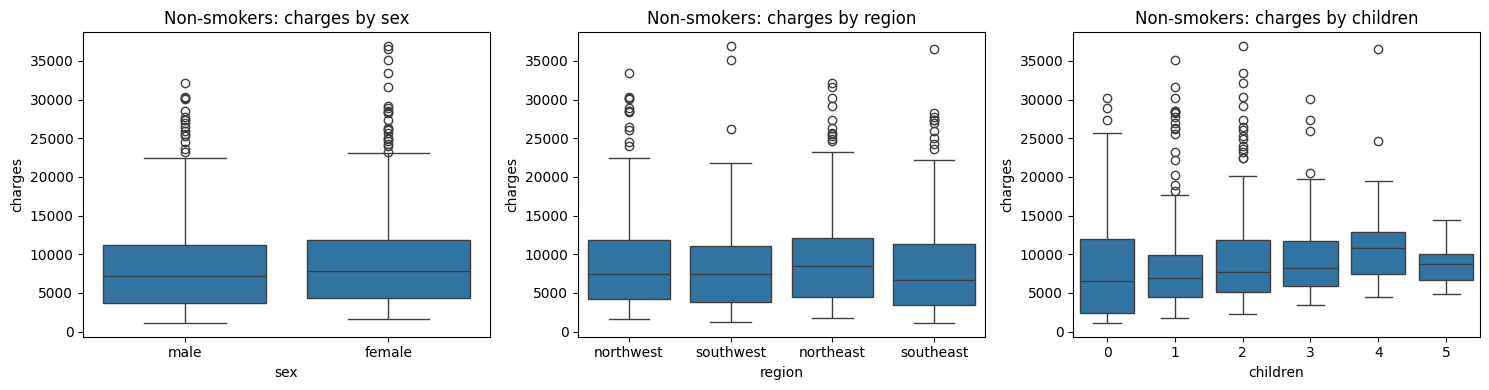

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, column in zip(axes, ["sex", "region", "children"]):
    sns.boxplot(data=train[train["smoker"] == "no"], x=column, y="charges", color="tab:blue", ax=ax)
    ax.set(title=f"Non-smokers: charges by {column}")
fig.tight_layout()
plt.show()

Among non-smokers (to avoid mixing in the smoking effect), sex and region make little visible difference. The number of children has a weak upward trend in the median. The many points above the boxes are the non-smokers of the middle band: people whose costs are much higher than their age would suggest, for reasons that are not in the data (for example a chronic illness).

## 2. A first additive model

We start with the model that a first analysis would fit: every variable enters linearly, the categorical ones as dummy variables.

In [6]:
additive = smf.ols("charges ~ age + sex + bmi + children + smoker + region", data=train).fit()
print(f"R2 = {additive.rsquared:.3f}, residual standard error = ${np.sqrt(additive.scale):,.0f}")
print(additive.summary().tables[1])

R2 = 0.736, residual standard error = $6,291
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept            -1.18e+04   1182.735     -9.979      0.000   -1.41e+04   -9482.048
sex[T.male]            90.3280    400.937      0.225      0.822    -696.453     877.109
smoker[T.yes]        2.378e+04    496.825     47.866      0.000    2.28e+04    2.48e+04
region[T.northwest]  -248.4037    569.868     -0.436      0.663   -1366.687     869.879
region[T.southeast] -1126.6877    567.872     -1.984      0.048   -2241.055     -12.320
region[T.southwest] -1303.0850    566.795     -2.299      0.022   -2415.338    -190.832
age                   260.0618     14.306     18.178      0.000     231.988     288.136
bmi                   334.9537     33.981      9.857      0.000     268.271     401.637
children              509.1634    165.349      3.079      0.002     184.689

The coefficients agree with the plots: smoking adds about \$23,800 per year, each year of age about \$260, each BMI point about \$335. Sex is not significant, and two regions are barely significant. With $R^2 = 0.74$ the model looks reasonable, but a residual standard error of \$6,300 is large compared with the \$7k median cost of a non-smoker. The diagnostic plots show why.

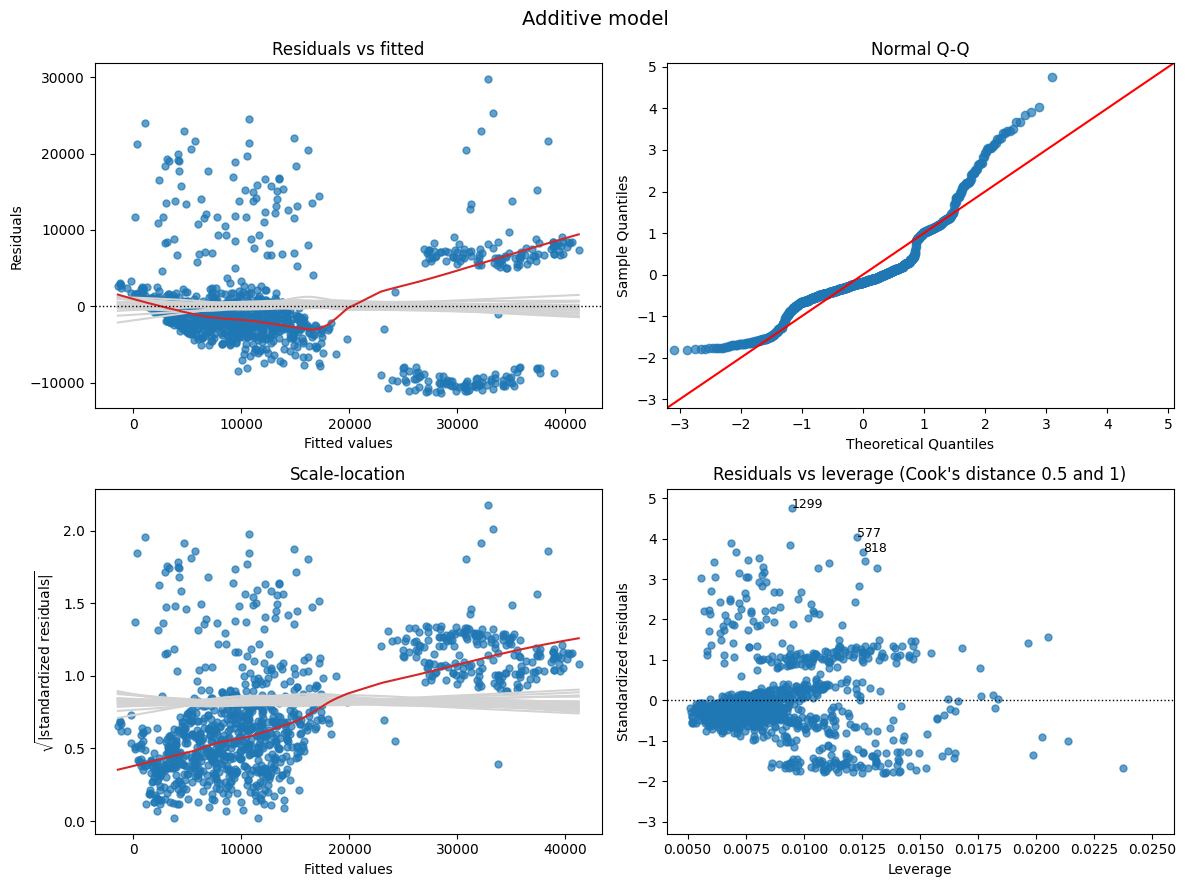

In [7]:
diagnostic_plots(additive, title="Additive model")

The residuals are far from random noise:

- **residuals vs fitted** shows separate clouds instead of one band around zero. Above fitted values of \$20k (the smokers) the residuals fall into two groups, at about +\$7k and −\$10k, and the red smoother is far outside the grey band of a correct model;
- the **Q-Q plot** has an S shape, and the **scale-location** plot shows a spread that grows with the fitted values.

A single additive smoking effect cannot be right if smokers fall into two groups with opposite errors. The next plot splits the residuals by the two variables the exploration pointed to.

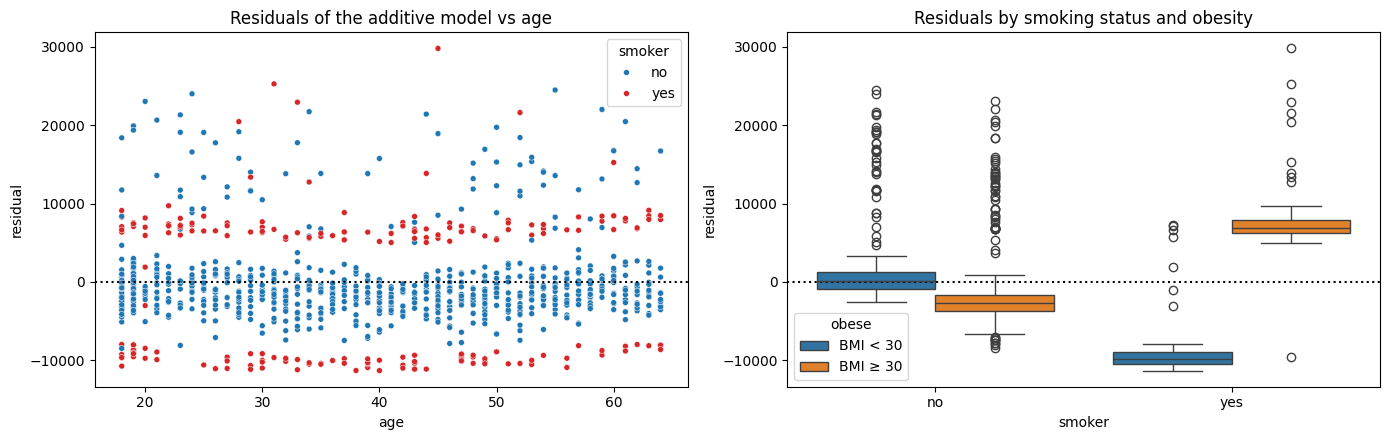

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
resid = train.assign(residual=additive.resid, obese=np.where(train["bmi"] >= 30, "BMI ≥ 30", "BMI < 30"))
sns.scatterplot(data=resid, x="age", y="residual", hue="smoker", palette=palette, s=18, ax=axes[0])
axes[0].axhline(0, color="black", ls=":")
axes[0].set(title="Residuals of the additive model vs age")
sns.boxplot(data=resid, x="smoker", y="residual", hue="obese", ax=axes[1])
axes[1].axhline(0, color="black", ls=":")
axes[1].set(title="Residuals by smoking status and obesity")
fig.tight_layout()
plt.show()

The two smoker clouds are exactly **obese and non-obese smokers**: the model overestimates the costs of smokers with BMI below 30 by about \$10k and underestimates those of obese smokers by about \$7k. A linear BMI term cannot capture an effect that only exists for smokers and acts as a jump at BMI 30. This is an **interaction**: the effect of BMI depends on smoking status.

Against age, the residuals show no strong pattern, but the lowest band in the exploration plot curved slightly upwards, so we also try a quadratic term in age.

## 3. Adding what the plots show

We encode the two patterns directly:

- `obese` is 1 when BMI ≥ 30, and the term `smoker:obese` lets obese smokers have their own extra cost;
- `I(age**2)` lets the cost grow faster with age.

We add them one at a time and compare the models on the training set with the adjusted $R^2$ and AIC, then check the prediction error on the test set, which none of the models has seen.

In [9]:
for df in (train, test):
    df["obese"] = (df["bmi"] >= 30).astype(int)

formulas = {
    "additive": "charges ~ age + sex + bmi + children + smoker + region",
    "+ smoker x obese": "charges ~ age + sex + bmi + children + smoker * obese + region",
    "+ age squared": "charges ~ age + I(age**2) + sex + bmi + children + smoker * obese + region",
    "- sex": "charges ~ age + I(age**2) + bmi + children + smoker * obese + region",
    "final: - sex - region": "charges ~ age + I(age**2) + bmi + children + smoker * obese",
}
fits = {name: smf.ols(f, data=train).fit() for name, f in formulas.items()}

def rmse(y_true, y_pred):
    return np.sqrt(np.mean((np.asarray(y_true) - np.asarray(y_pred)) ** 2))

comparison = pd.DataFrame({
    name: {
        "parameters": len(m.params),
        "adjusted R2": m.rsquared_adj,
        "AIC": m.aic,
        "test RMSE ($)": rmse(test["charges"], m.predict(test)),
        "test MAE ($)": np.mean(np.abs(test["charges"] - m.predict(test))),
    }
    for name, m in fits.items()
}).T
comparison.round({"parameters": 0, "adjusted R2": 3, "AIC": 0, "test RMSE ($)": 0, "test MAE ($)": 0})

,parameters,adjusted R2,AIC,test RMSE ($),test MAE ($)
additive,9.0,0.734,20381.0,5363.0,3820.0
+ smoker x obese,11.0,0.845,19838.0,3462.0,2085.0
+ age squared,12.0,0.848,19822.0,3427.0,2035.0
- sex,11.0,0.848,19822.0,3441.0,2063.0
final: - sex - region,8.0,0.846,19833.0,3393.0,2085.0


- The **smoker × obese interaction** is the big step: the adjusted $R^2$ goes from 0.73 to 0.85 and the test RMSE drops from \$5,360 to \$3,460, a 35% reduction with only two more parameters.
- The **squared age** helps a little (AIC 19,822 against 19,838).
- Removing **sex** changes nothing. Removing **region** too gives a slightly higher AIC but the lowest test error.

The last two rows disagree, so we test region directly with a partial F-test.

In [10]:
from statsmodels.stats.anova import anova_lm

f_tests = anova_lm(fits["final: - sex - region"], fits["- sex"], fits["+ age squared"])
f_tests.index = ["final", "+ region", "+ region + sex"]
print(f_tests[["df_diff", "F", "Pr(>F)"]].round(4))
print()
print(fits["- sex"].params.filter(like="region").round(0))

                df_diff       F  Pr(>F)
final               0.0     NaN     NaN
+ region            3.0  5.4451  0.0010
+ region + sex      1.0  2.2857  0.1309

region[T.northwest]    -192.0
region[T.southeast]    -950.0
region[T.southwest]   -1554.0
dtype: float64


On the training data region is significant (p = 0.001): people in the south-west cost about \$1,500 less than in the north-east, other things being equal. Sex is not (p = 0.13). On the test set, however, adding region does not reduce the error (\$3,441 against \$3,393). A real but small effect, worth less than half of the remaining residual error, does not justify three more parameters in a model meant for prediction. We keep the simpler model and note that a regional difference of this size exists.

In [11]:
final = fits["final: - sex - region"]
print(final.summary().tables[1])

                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept             624.1690   1680.773      0.371      0.710   -2674.102    3922.440
smoker[T.yes]        1.332e+04    547.648     24.318      0.000    1.22e+04    1.44e+04
age                   -46.7854     75.214     -0.622      0.534    -194.383     100.812
I(age ** 2)             3.9215      0.940      4.174      0.000       2.078       5.765
bmi                    83.4695     41.189      2.026      0.043       2.641     164.298
children              741.0632    133.261      5.561      0.000     479.559    1002.568
obese                -666.8258    527.380     -1.264      0.206   -1701.731     368.080
smoker[T.yes]:obese  1.963e+04    751.892     26.108      0.000    1.82e+04    2.11e+04


The final model is easy to read:

- a smoker with BMI below 30 costs about **\$13,300** more than a non-smoker; an obese smoker costs a further **\$19,600** more, so about \$33,000 more than a non-smoker in total. For non-smokers, obesity has no significant effect (−\$670, p = 0.21);
- age acts through the square: compared with age 0, the age terms add about \$600 at 20, \$4,400 at 40 and \$11,300 at 60, so each additional year costs more as people get older. The linear term on its own is not significant, but it is kept with its square;
- each child covered adds about \$740; BMI has a small residual effect (\$83 per point) on top of the obesity threshold.

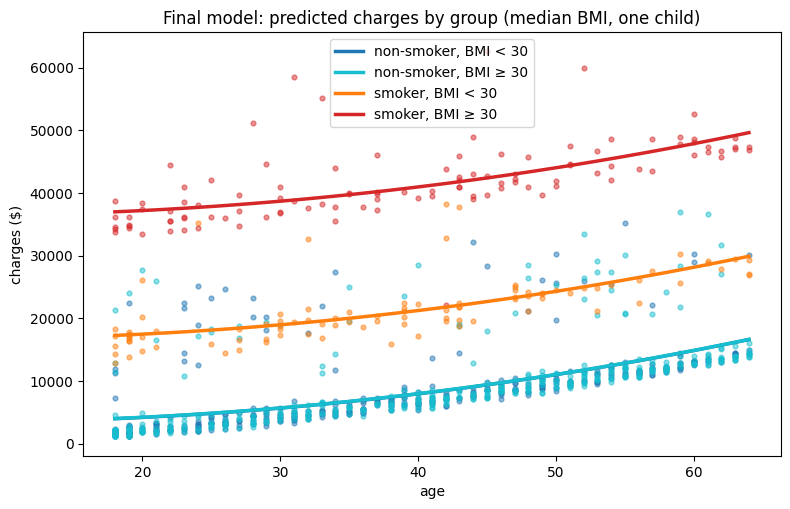

In [12]:
fig, ax = plt.subplots(figsize=(9, 5.5))
groups = {
    ("no", 0): ("non-smoker, BMI < 30", "tab:blue"),
    ("no", 1): ("non-smoker, BMI ≥ 30", "tab:cyan"),
    ("yes", 0): ("smoker, BMI < 30", "tab:orange"),
    ("yes", 1): ("smoker, BMI ≥ 30", "tab:red"),
}
ages = np.arange(18, 65)
for (smoker, obese), (label, color) in groups.items():
    g = train[(train["smoker"] == smoker) & (train["obese"] == obese)]
    ax.scatter(g["age"], g["charges"], s=12, color=color, alpha=0.5)
    grid = pd.DataFrame({"age": ages, "bmi": g["bmi"].median(), "children": 1, "smoker": smoker, "obese": obese})
    ax.plot(ages, final.predict(grid), color=color, lw=2.5, label=label)
ax.set(xlabel="age", ylabel="charges ($)", title="Final model: predicted charges by group (median BMI, one child)")
ax.legend()
plt.show()

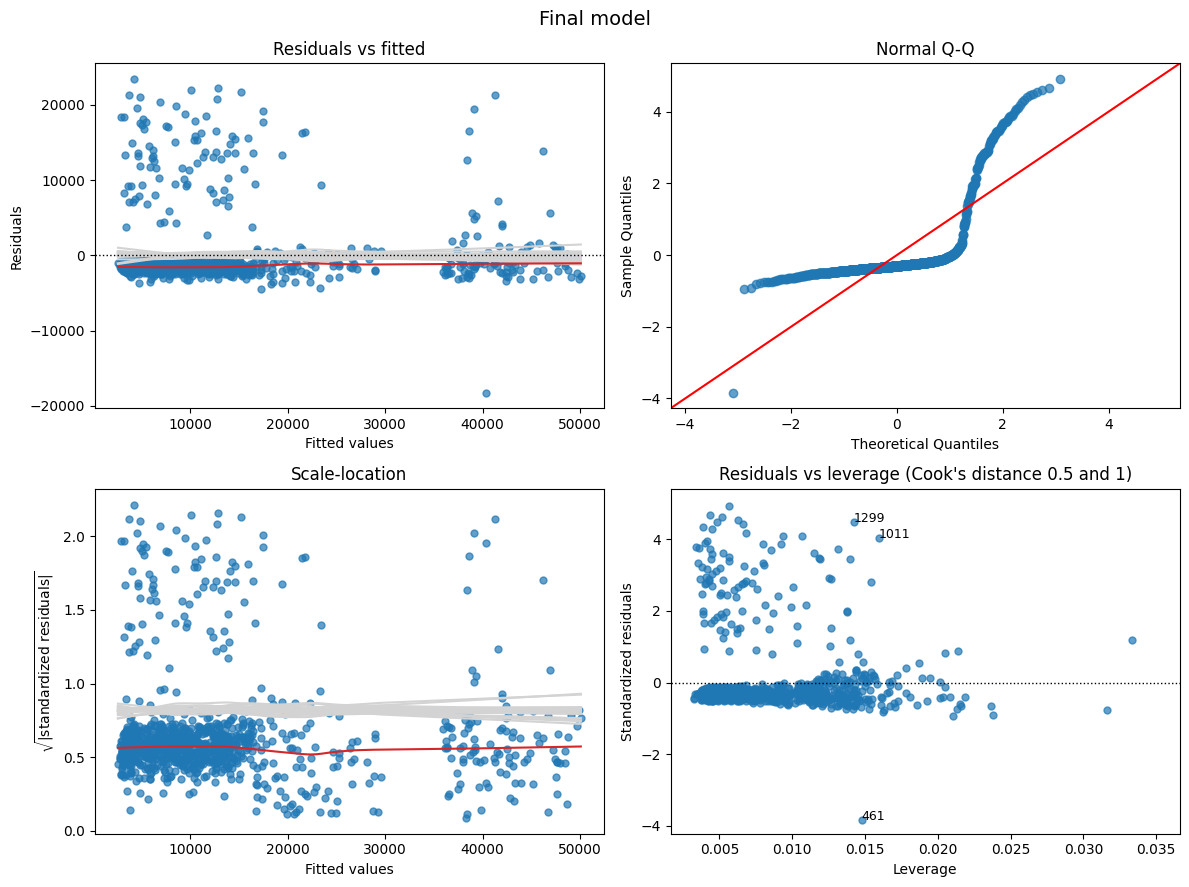

In [13]:
diagnostic_plots(final, title="Final model")

The four groups are now fitted well (the two non-smoker lines almost coincide). The residual plots are very different from before: the red smoothers are flat and inside the grey band, and 87% of the residuals are within ±\$3,000.

What remains is a clear **asymmetry**: about 10% of the people, mostly non-smokers, cost \$5–25k more than predicted. These are the points of the middle band, and nothing in the data tells them apart from the others. The Q-Q plot reflects this: the residuals are not normal but strongly right-skewed. The least squares fit is still the best linear predictor of the *mean*, but the normal-theory prediction intervals would be wrong, and, because least squares chases these large positive errors, the typical person is **overestimated** by about \$1,400 (the median residual). This matters in section 5.

## 4. Ridge, lasso and a random forest

Notebook 05 showed that regularization pays off when there are many predictors for few observations. Here we have the opposite situation: about 1,000 people and fewer than 15 parameters. We still fit ridge and lasso on all the terms of the richest model (including sex and region) to see whether the lasso drops the same variables as our manual selection.

A **random forest** is also included as a flexible model that can find interactions and curvature on its own, without being told where to look.

In [14]:
richest = "charges ~ age + I(age**2) + sex + bmi + children + smoker * obese + region"
y_train, X_train = dmatrices(richest, train, return_type="dataframe")
y_test, X_test = dmatrices(richest, test, return_type="dataframe")
X_train, X_test = X_train.drop(columns="Intercept"), X_test.drop(columns="Intercept")
y_train, y_test = y_train["charges"], y_test["charges"]

ridge = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-3, 4, 200), cv=10)).fit(X_train, y_train)
lasso = make_pipeline(StandardScaler(), LassoCV(cv=10, random_state=0, max_iter=100_000)).fit(X_train, y_train)

raw = ["age", "sex", "bmi", "children", "smoker", "region"]
X_raw_train = pd.get_dummies(train[raw], drop_first=True, dtype=int)
X_raw_test = pd.get_dummies(test[raw], drop_first=True, dtype=int)
forest = RandomForestRegressor(n_estimators=500, min_samples_leaf=3, random_state=0).fit(X_raw_train, train["charges"])

scores = {
    "mean only (baseline)": rmse(y_test, np.full(len(y_test), y_train.mean())),
    "additive model": comparison.loc["additive", "test RMSE ($)"],
    "final model (section 3)": comparison.loc["final: - sex - region", "test RMSE ($)"],
    f"ridge (lambda = {ridge[-1].alpha_:.2f})": rmse(y_test, ridge.predict(X_test)),
    f"lasso (lambda = {lasso[-1].alpha_:.1f})": rmse(y_test, lasso.predict(X_test)),
    "random forest, raw variables": rmse(test["charges"], forest.predict(X_raw_test)),
}
pd.Series(scores, name="test RMSE ($)").round(0)

mean only (baseline)            11878.0
additive model                   5363.0
final model (section 3)          3393.0
ridge (lambda = 5.81)            3425.0
lasso (lambda = 26.1)            3429.0
random forest, raw variables     3768.0
Name: test RMSE ($), dtype: float64

In [15]:
coefs = pd.DataFrame({
    "least squares": make_pipeline(StandardScaler(), LinearRegression()).fit(X_train, y_train)[-1].coef_,
    "ridge": ridge[-1].coef_,
    "lasso": lasso[-1].coef_,
}, index=X_train.columns)
coefs.round(0)

,least squares,ridge,lasso
sex[T.male],-229.0,-220.0,-195.0
smoker[T.yes],5375.0,5369.0,5373.0
region[T.northwest],-77.0,-68.0,-0.0
region[T.southeast],-423.0,-409.0,-323.0
region[T.southwest],-661.0,-649.0,-577.0
age,-718.0,217.0,0.0
I(age ** 2),4452.0,3505.0,3714.0
bmi,645.0,621.0,488.0
children,908.0,854.0,840.0
obese,-387.0,-344.0,-224.0


- **Regularization makes no difference here.** Ridge and lasso choose small penalties and reach the same test error as the final model. With 1,000 observations and 11 predictors, least squares already estimates the coefficients precisely; there is little variance to reduce (notebook 05 showed the opposite situation).
- **The lasso agrees with the manual selection** only partly: it sets the north-west region and the linear age term to zero, but keeps sex and the two southern regions with small coefficients. On the training data their contribution is not exactly zero, as the F-test showed for region.
- **The random forest is worse** (\$3,770) than the linear model with the right interaction (\$3,390), even though it can, in principle, discover the interaction by itself. With 1,000 observations, a model with eight well-chosen terms is both more accurate and much easier to explain.

## 5. Predicting a cost band

An insurer may only need to know in which band a person's costs will fall, for example under \$5k, \$5–10k, \$10–20k or over \$20k. This turns the problem into a classification with four roughly balanced classes. Two ways to get a band:

- train a **classifier** directly on the bands (a random forest);
- take a **regression** model and cut its predictions at the same thresholds.

In [16]:
bins, labels = [0, 5_000, 10_000, 20_000, np.inf], ["< 5k", "5-10k", "10-20k", "> 20k"]
to_band = lambda charges: pd.cut(np.clip(charges, 1, None), bins, labels=labels)
band_train, band_test = to_band(train["charges"]), to_band(test["charges"])
print(band_train.value_counts(normalize=True).round(2).to_dict())

classifier = RandomForestClassifier(n_estimators=500, min_samples_leaf=3, random_state=0).fit(X_raw_train, band_train)
# same terms as the final model, fitted by minimizing the absolute errors instead of the squared errors
y_final, X_final = dmatrices(formulas["final: - sex - region"], train, return_type="dataframe")
_, X_final_test = dmatrices(formulas["final: - sex - region"], test, return_type="dataframe")
median_reg = QuantileRegressor(quantile=0.5, alpha=0, fit_intercept=False, solver="highs").fit(X_final, y_final["charges"])
predicted_bands = {
    "random forest classifier": classifier.predict(X_raw_test),
    "final model (least squares), cut into bands": to_band(final.predict(test)),
    "same model fitted to the median, cut into bands": to_band(median_reg.predict(X_final_test)),
}
pd.Series({name: np.mean(np.asarray(p) == np.asarray(band_test)) for name, p in predicted_bands.items()},
          name="test accuracy").round(3)

{'10-20k': 0.26, '5-10k': 0.26, '< 5k': 0.26, '> 20k': 0.21}


random forest classifier                           0.922
final model (least squares), cut into bands        0.740
same model fitted to the median, cut into bands    0.925
Name: test accuracy, dtype: float64

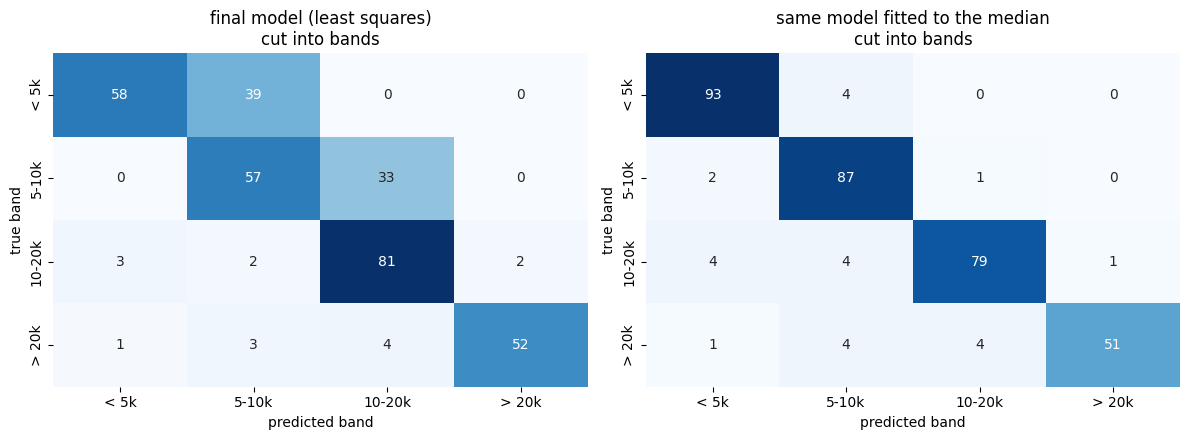

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, name in zip(axes, ["final model (least squares), cut into bands", "same model fitted to the median, cut into bands"]):
    mat = confusion_matrix(band_test, np.asarray(predicted_bands[name]), labels=labels)
    sns.heatmap(mat, annot=True, fmt="d", cbar=False, cmap="Blues", xticklabels=labels, yticklabels=labels, ax=ax)
    ax.set(xlabel="predicted band", ylabel="true band", title=name.replace(", cut", "\ncut"))
fig.tight_layout()
plt.show()

The random forest classifier is correct for 92% of the test set, while the least squares model cut into bands gets only 74%. The confusion matrix on the left shows where: almost all errors put people **one band too high** (39 of the 97 people under \$5k, 33 of the 90 between \$5k and \$10k). This is the overestimation seen in the final diagnostics: least squares predicts the mean, and the mean is pulled up by the 10% of people with unexplained high costs.

For a band, the right target is the **typical** cost, not the mean. Fitting the same eight terms by minimizing the absolute errors (median regression) is enough: the accuracy rises to 92.5%, as good as the random forest, and the errors become symmetric. There is no need for a separate classifier: a regression model with the right loss already gives the bands.

## Summary

- **Smoking, age and the combination of smoking with obesity** explain most of the variation in medical costs. Sex and region add little or nothing.
- The **residual diagnostics** of the first additive model pointed directly to the missing interaction: smokers split into two groups with opposite errors. Adding a single smoker × obese term reduced the test error by 35%.
- A small, well-specified linear model beats a **random forest** on this data, and **ridge and lasso** add nothing when observations are many and predictors few.
- The remaining errors are **skewed**: about 10% of people cost much more than any variable in the data can explain. This makes least squares overestimate typical costs, which shows up clearly when predictions are cut into **cost bands**. Choosing the loss to match the question (the median instead of the mean) fixes it without changing the model.